# Chapter 9: Design That Communicates

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 9.1 Cutting Clutter

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

plt.style.use('book.mplstyle')

In [2]:
products = pd.read_csv('product_sales.csv')
by_revenue = products.sort_values('revenue', ascending=False)
by_revenue

,product,units,revenue
0,Webcam,212,54900
1,Keyboard,388,50040
3,Headphones,251,37650
2,Monitor,96,33500
4,USB Cable,1240,24680
5,Mouse,530,15370
6,Laptop Stand,174,8530


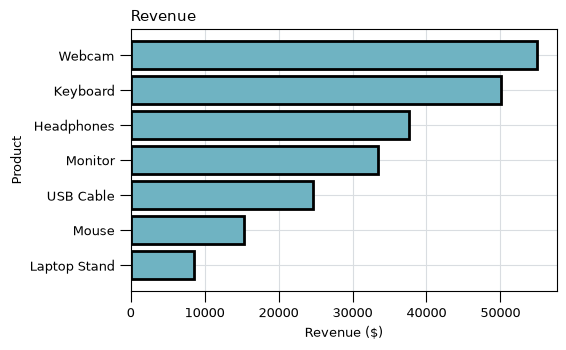

In [3]:
fig, ax = plt.subplots()
ax.barh(by_revenue['product'], by_revenue['revenue'],
        color='#6fb3c2', edgecolor='black', linewidth=2)
ax.grid(True)
ax.invert_yaxis()
ax.tick_params(length=8)
ax.set_title('Revenue')
ax.set_xlabel('Revenue ($)')
ax.set_ylabel('Product')
plt.show()

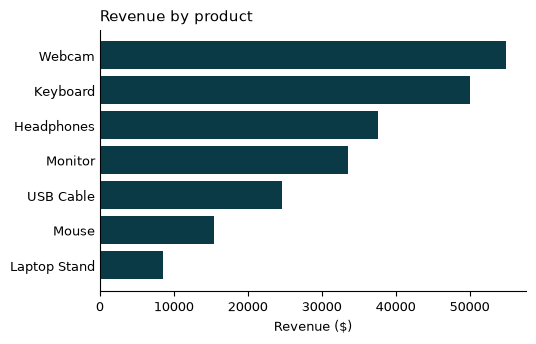

In [4]:
fig, ax = plt.subplots()
ax.barh(by_revenue['product'], by_revenue['revenue'], color='#0b3a47')
ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title('Revenue by product')
ax.set_xlabel('Revenue ($)')
plt.show()

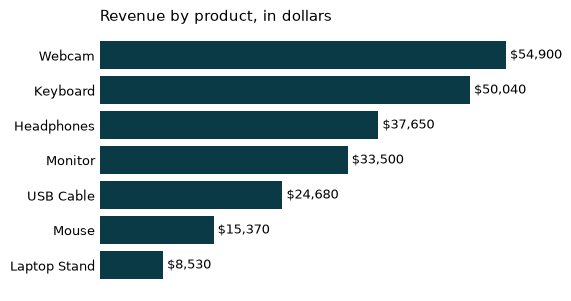

In [5]:
fig, ax = plt.subplots()
bars = ax.barh(by_revenue['product'], by_revenue['revenue'],
               color='#0b3a47')
ax.bar_label(bars, fmt='${:,.0f}', padding=3)
ax.invert_yaxis()
ax.spines[:].set_visible(False)
ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title('Revenue by product, in dollars')
plt.show()

## 9.2 Gray Plus One Highlight

In [6]:
channels = pd.read_csv('channel_monthly.csv')
channels.head(3)

,month,Online,In store,Phone
0,Jan,15100,8900,2600
1,Feb,14600,8100,2500
2,Mar,17800,9300,2700


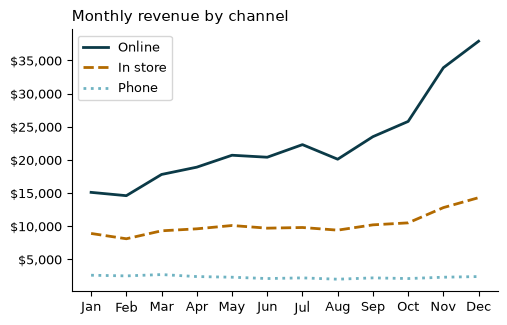

In [7]:
fig, ax = plt.subplots()
for name in ['Online', 'In store', 'Phone']:
    ax.plot(channels['month'], channels[name], label=name)
ax.set_title('Monthly revenue by channel')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
plt.show()

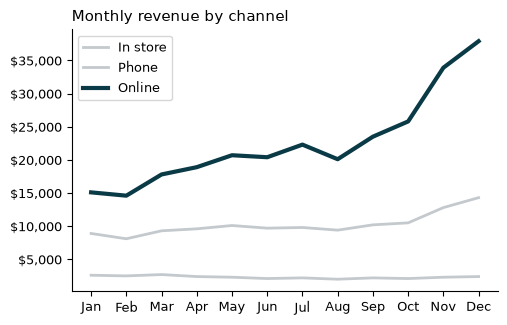

In [8]:
fig, ax = plt.subplots()
for name in ['In store', 'Phone']:
    ax.plot(channels['month'], channels[name], color='#c4c9ce',
            linestyle='-', label=name)
ax.plot(channels['month'], channels['Online'], color='#0b3a47',
        linestyle='-', linewidth=3, label='Online')
ax.set_title('Monthly revenue by channel')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
plt.show()

## 9.3 Direct Labels Instead of Legends

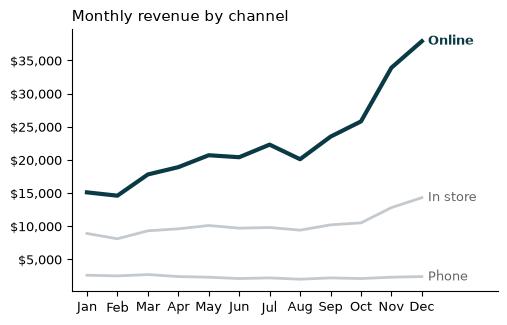

In [9]:
fig, ax = plt.subplots()
for name in ['In store', 'Phone']:
    ax.plot(channels['month'], channels[name], color='#c4c9ce',
            linestyle='-')
    ax.text(11.2, channels[name].iloc[-1], name, color='0.4',
            va='center')
ax.plot(channels['month'], channels['Online'], color='#0b3a47',
        linestyle='-', linewidth=3)
ax.text(11.2, channels['Online'].iloc[-1], 'Online', color='#0b3a47',
        fontweight='bold', va='center')
ax.set_xlim(-0.5, 13.5)
ax.set_title('Monthly revenue by channel')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 9.4 Titles That State the Finding

In [10]:
channels.loc[[0, 11], ['month', 'Online', 'Phone']]

,month,Online,Phone
0,Jan,15100,2600
11,Dec,37900,2400


In [11]:
channels[['Online', 'Phone']].max()

Online    37900
Phone      2700
dtype: int64

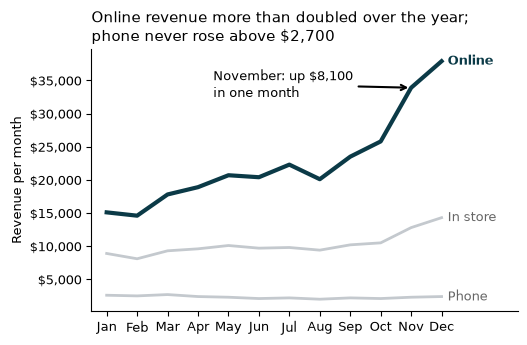

In [12]:
fig, ax = plt.subplots()
for name in ['In store', 'Phone']:
    ax.plot(channels['month'], channels[name], color='#c4c9ce',
            linestyle='-')
    ax.text(11.2, channels[name].iloc[-1], name, color='0.4',
            va='center')
ax.plot(channels['month'], channels['Online'], color='#0b3a47',
        linestyle='-', linewidth=3)
ax.text(11.2, channels['Online'].iloc[-1], 'Online', color='#0b3a47',
        fontweight='bold', va='center')
ax.annotate('November: up $8,100\nin one month',
            xy=(10, 33900), xytext=(3.5, 32500),
            arrowprops={'arrowstyle': '->', 'lw': 1.5})
ax.set_xlim(-0.5, 13.5)
ax.set_title('Online revenue more than doubled over the year;\n'
             'phone never rose above $2,700')
ax.set_ylabel('Revenue per month')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 9.5 Charts for Black and White and for Colorblind Readers

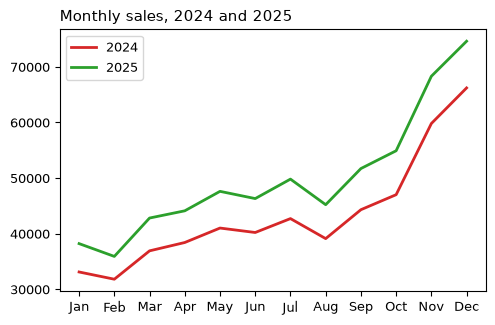

In [13]:
sales = pd.read_csv('monthly_sales.csv')
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2024'], color='tab:red',
        linestyle='-', label='2024')
ax.plot(sales['month'], sales['sales_2025'], color='tab:green',
        linestyle='-', label='2025')
ax.set_title('Monthly sales, 2024 and 2025')
ax.legend()
plt.show()

In [14]:
bool((sales['sales_2025'] > sales['sales_2024']).all())

True

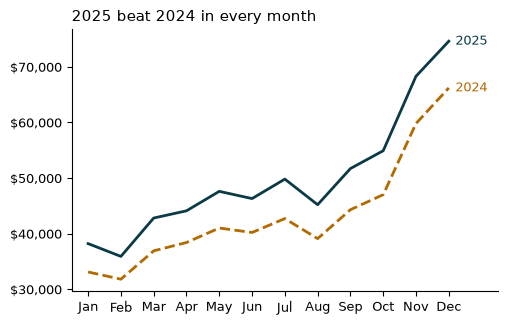

In [15]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2024'], color='#b26a00',
        linestyle='--')
ax.plot(sales['month'], sales['sales_2025'], color='#0b3a47',
        linestyle='-')
ax.text(11.2, sales['sales_2024'].iloc[-1], '2024', color='#b26a00',
        va='center')
ax.text(11.2, sales['sales_2025'].iloc[-1], '2025', color='#0b3a47',
        va='center')
ax.set_xlim(-0.5, 12.5)
ax.set_title('2025 beat 2024 in every month')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
plt.show()